In [1]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import DDPG
# from stable_baselines3.common.noise import NormalActionNoise, OrnsteinUhlenbeckActionNoise
import torch as th
import os

In [2]:
import gym
import gym_mppt
from gym import envs
env = gym.make("mppt_shaded-v4")

num_obs = env.observation_space.shape[0]
print("Size of Observation Space ->  {}".format(num_obs))
print(env.observation_space)

print()

num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))
print(env.action_space)

Size of Observation Space ->  3
Box([  0. -inf -inf], [212.  inf  inf], (3,), float32)

Size of Action Space ->  1
Box([-5.], [5.], (1,), float32)


C:\Users\archi\anaconda3\envs\BTPtorch\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(


In [3]:
## LAYER_1 = 400
## LAYER_2 = 300
## LAYER_3 = 300
# keep_rate = 0.8
# LAMBDA = 0.00001 # regularization term
## GAMMA = 0.99
# '/actor' random_uniform_initializer(minval=-0.003, maxval=0.003)
## ACTOR_LEARNING_RATE = 0.0001
## CRITIC_LEARNING_RATE =  0.001
## TAU = 0.001
## epochs = 10000   -> no. of iterations
## BUFFER_SIZE = 50000
# RANDOM_SEED = 51234
## MINIBATCH_SIZE = 64# 32 # 5
# OUNoise(action_dim, mu = 0.0)

# epsilon = 1.0
# min_epsilon = 0.1
# EXPLORE = 15000
# epsilon -= (epsilon/EXPLORE)
# epsilon = np.maximum(min_epsilon,epsilon)
# if random.random() < epsilon:
#     action = random.uniform(min_action,max_action)

In [4]:
policy_kwargs = dict(activation_fn=th.nn.ReLU, net_arch=[400, 300, 300])

# Create the agent
model = DDPG("MlpPolicy",
            env,
            policy_kwargs=policy_kwargs,
            batch_size=int(64),
            gamma=0.99,
            learning_rate=1e-4,
            tau=0.001,
            buffer_size=50000,
            verbose=1,
            device="cuda")

model.learn(total_timesteps=int(100*10000), progress_bar=True, reset_num_timesteps=False)

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


Output()

c:\users\archi\python code\btp\ppo_new_win\mppt-gym_v4\gym_mppt\envs\mppt_env_shaded4.py:41: RuntimeWarning: 
overflow encountered in exp
  I = self.Np * Iph - self.Np * Irs * (np.exp(self.q / (self.k * Tcell * self.A) * vx * (1/SH) / self.Ns) - 1)

c:\users\archi\python code\btp\ppo_new_win\mppt-gym_v4\gym_mppt\envs\mppt_env_shaded4.py:57: RuntimeWarning: 
invalid value encountered in subtract
  In = I - fv/fdv

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | -24.2    |
| time/              |          |
|    episodes        | 4        |
|    fps             | 84       |
|    time_elapsed    | 4        |
|    total_timesteps | 400      |
| train/             |          |
|    actor_loss      | 0.286    |
|    critic_loss     | 0.0303   |
|    learning_rate   | 0.0001   |
|    n_updates       | 200      |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | -5.72    |
| time/              |          |
|    episodes        | 8        |
|    fps             | 75       |
|    time_elapsed    | 10       |
|    total_timesteps | 800      |
| train/             |          |
|    actor_loss      | 0.0421   |
|    critic_loss     | 0.00762  |
|    learning_rate   | 0.0001   |
|    n_updates       | 600      |
--------------

...

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 14.7     |
| time/              |          |
|    episodes        | 9692     |
|    fps             | 67       |
|    time_elapsed    | 14366    |
|    total_timesteps | 969200   |
| train/             |          |
|    actor_loss      | -8.29    |
|    critic_loss     | 0.675    |
|    learning_rate   | 0.0001   |
|    n_updates       | 969000   |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 14.6     |
| time/              |          |
|    episodes        | 9696     |
|    fps             | 67       |
|    time_elapsed    | 14371    |
|    total_timesteps | 969600   |
| train/             |          |
|    actor_loss      | -8.29    |
|    critic_loss     | 0.699    |
|    learning_rate   | 0.0001   |
|    n_updates       | 969400   |
--------------

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16.2     |
| time/              |          |
|    episodes        | 9760     |
|    fps             | 67       |
|    time_elapsed    | 14467    |
|    total_timesteps | 976000   |
| train/             |          |
|    actor_loss      | -8.27    |
|    critic_loss     | 0.668    |
|    learning_rate   | 0.0001   |
|    n_updates       | 975800   |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16.1     |
| time/              |          |
|    episodes        | 9764     |
|    fps             | 67       |
|    time_elapsed    | 14472    |
|    total_timesteps | 976400   |
| train/             |          |
|    actor_loss      | -8.27    |
|    critic_loss     | 0.72     |
|    learning_rate   | 0.0001   |
|    n_updates       | 976200   |
--------------

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16       |
| time/              |          |
|    episodes        | 9828     |
|    fps             | 67       |
|    time_elapsed    | 14568    |
|    total_timesteps | 982800   |
| train/             |          |
|    actor_loss      | -8.25    |
|    critic_loss     | 0.66     |
|    learning_rate   | 0.0001   |
|    n_updates       | 982600   |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16.4     |
| time/              |          |
|    episodes        | 9832     |
|    fps             | 67       |
|    time_elapsed    | 14573    |
|    total_timesteps | 983200   |
| train/             |          |
|    actor_loss      | -8.27    |
|    critic_loss     | 0.549    |
|    learning_rate   | 0.0001   |
|    n_updates       | 983000   |
--------------

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16.3     |
| time/              |          |
|    episodes        | 9896     |
|    fps             | 67       |
|    time_elapsed    | 14668    |
|    total_timesteps | 989600   |
| train/             |          |
|    actor_loss      | -8.24    |
|    critic_loss     | 0.602    |
|    learning_rate   | 0.0001   |
|    n_updates       | 989400   |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16       |
| time/              |          |
|    episodes        | 9900     |
|    fps             | 67       |
|    time_elapsed    | 14674    |
|    total_timesteps | 990000   |
| train/             |          |
|    actor_loss      | -8.23    |
|    critic_loss     | 0.62     |
|    learning_rate   | 0.0001   |
|    n_updates       | 989800   |
--------------

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 15.6     |
| time/              |          |
|    episodes        | 9964     |
|    fps             | 67       |
|    time_elapsed    | 14771    |
|    total_timesteps | 996400   |
| train/             |          |
|    actor_loss      | -8.19    |
|    critic_loss     | 0.649    |
|    learning_rate   | 0.0001   |
|    n_updates       | 996200   |
---------------------------------
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | 16.1     |
| time/              |          |
|    episodes        | 9968     |
|    fps             | 67       |
|    time_elapsed    | 14777    |
|    total_timesteps | 996800   |
| train/             |          |
|    actor_loss      | -8.17    |
|    critic_loss     | 0.735    |
|    learning_rate   | 0.0001   |
|    n_updates       | 996600   |
--------------

In [5]:
dire = os.getcwd()
model.save(dire + '\\ddpg_trained_model1')

In [6]:
dire = os.getcwd()
# env = make_vec_env("mppt_shaded-v3", n_envs=1)
env.training = False
model = DDPG.load(dire + '\\ddpg_trained_model1')
model.set_env(env)

Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.


1


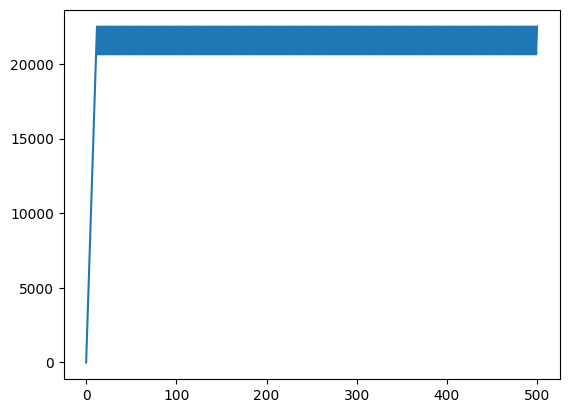

In [12]:
for j in range(1):
    print(j+1)
    obs = env.reset()
    obs = env.render([10,10,10,10,10,10,25,1000])
    powlst = [0.0]
    normpowlst = [0.0]
    voltlst = [0.0]
    for i in range(500):
        action, _state = model.predict(obs)
        obs, rewards, done, info = env.step(action)
        voltlst.append(float(info["Voltage"]))
        powlst.append(float(info["Power"]))
        normpowlst.append(float(info["NormPower"]))
#     plt.plot(normpowlst)
    plt.plot(powlst)

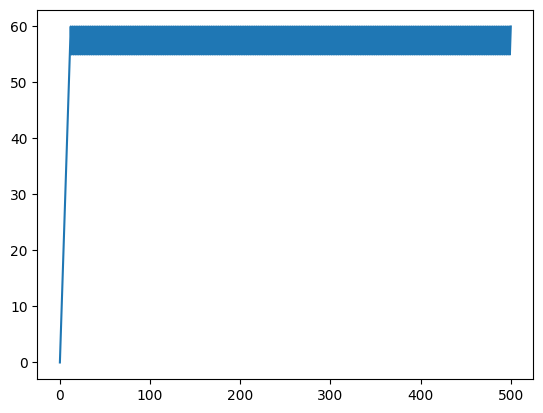

In [13]:
plt.plot(voltlst)

In [14]:
print(voltlst)

[0.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 35.0, 40.0, 45.0, 50.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0, 55.0, 60.0,